### Data splits
Load `features_arakan.csv`, drop warmup NaNs from lag features, split temporally: train 2024, val 2025-H1, test 2025-H2. No shuffling to avoid leakage.

In [34]:
import pandas as pd

df = pd.read_csv("../data/processed/features_arakan.csv", parse_dates=["timestamp"])
df = df.dropna().set_index("timestamp").sort_index()
train = df.loc["2024-01-01":"2024-12-31"]
val = df.loc["2025-01-01":"2025-06-30"]
test = df.loc["2025-07-01":]
print(train.shape, val.shape, test.shape)
print(train["load_kw"].describe())

(8616, 25) (4344, 25) (4416, 25)
count    8616.000000
mean     1749.854596
std       358.867098
min       940.900000
25%      1475.075000
50%      1724.100000
75%      2024.250000
max      3178.300000
Name: load_kw, dtype: float64


### Tabular features
Drop target `load_kw` and string label. 23 numeric inputs remain for XGBoost.

In [35]:
DROP = ["load_kw", "readiness_label"]
x_train, y_train = train.drop(columns=DROP), train['load_kw']
x_val, y_val = val.drop(columns=DROP), val["load_kw"]
x_test, y_test = test.drop(columns=DROP), test["load_kw"]
print(x_train.shape)

(8616, 23)


### XGBoost baseline (Stage 1)
300 trees, depth 6. Learns non-linear weather + calendar + lag interactions.

In [36]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    n_jobs=-1,
    random_state=42
)
model.fit(x_train, y_train, verbose=False)
pred_val = model.predict(x_val)
print(f"VAL RMSE {root_mean_squared_error(y_val, pred_val):.1f} MAE {mean_absolute_error(y_val, pred_val):.1f}")

VAL RMSE 90.6 MAE 53.3


### Baseline scores
TEST RMSE 87.7, MAE 52.4, MAPE 2.78%. Reference for hybrid comparison.

In [37]:
pred_test = model.predict(x_test)
from sklearn.metrics import mean_absolute_percentage_error
print(f"TEST RMSE {root_mean_squared_error(y_test, pred_test): .1f} MAE {mean_absolute_error(y_test, pred_test):.1f} MAPE {mean_absolute_percentage_error(y_test, pred_test)*100:.2f}%")

TEST RMSE  87.7 MAE 52.4 MAPE 2.78%


### Weakness analysis
Groups error by readiness code. Surge (1) MAE 279 vs routine (4) 42. Naive lag-1 MAE 134. Motivates LSTM Stage 2.

In [38]:
import pandas as pd
res = pd.DataFrame({"y": y_test, "pred": pred_test}, index=x_test.index)
res["ae"] = (res.y - res.pred).abs()
res["readiness"] = test.loc[res.index, "readiness_code"]
print(res.groupby("readiness")["ae"].mean())

from sklearn.metrics import mean_absolute_error
print("naive MAE", mean_absolute_error(y_test, x_test["load_lag_1h"]))

readiness
1    279.214714
2    109.473477
3     59.576122
4     42.250574
Name: ae, dtype: float64
naive MAE 134.55489130434782


### SHAP explainability
TreeExplainer on 500 test rows. Shows which weather/lag features drive predictions.

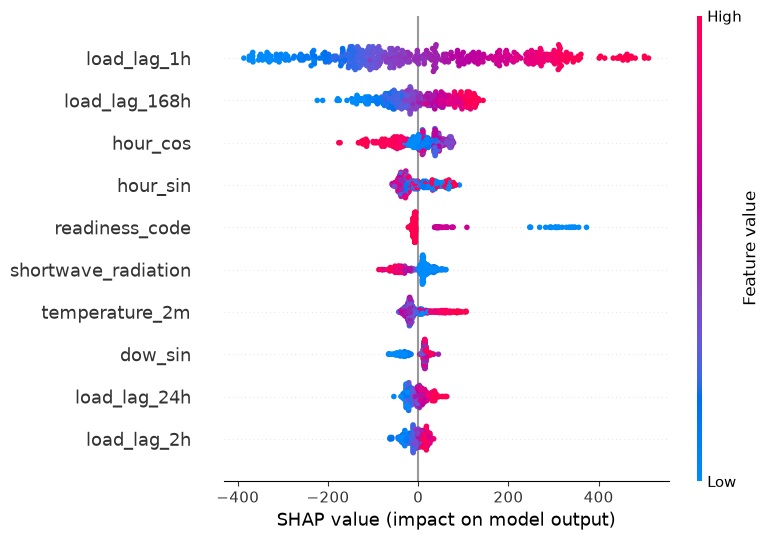

In [39]:
import shap
exp = shap.TreeExplainer(model)
sv = exp.shap_values(x_test.sample(500, random_state=42))
shap.summary_plot(sv, x_test.sample(500, random_state=42), max_display=10)

### Weighted retry
Sample weight 1/3/8/15 for readiness 4/3/2/1. Tests if upweighting surges helps.

In [40]:
w = train["readiness_code"].map({4:1, 3:3, 2:8, 1:15})
model2 = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)
model2.fit(x_train, y_train, sample_weight=w.loc[x_train.index])
pred2 = model2.predict(x_test)
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
print(f"RMSE {root_mean_squared_error(y_test, pred2):.1f} MAE {mean_absolute_error(y_test, pred2):.1f} MAPE {mean_absolute_percentage_error(y_test, pred2)*100:.2f}%")
pd.DataFrame({"ae": (y_test-pred2).abs(), "readiness": test.loc[x_test.index,"readiness_code"]}).groupby("readiness")["ae"].mean()

RMSE 86.6 MAE 52.4 MAPE 2.79%


readiness
1    270.738913
2    129.247431
3     59.510445
4     42.572992
Name: ae, dtype: float64

### Weighted scores
Prints RMSE/MAE/MAPE for weighted model.

In [41]:
print(f"RMSE {root_mean_squared_error(y_test, pred2):.1f} MAE {mean_absolute_error(y_test, pred2):.1f} MAPE {mean_absolute_percentage_error(y_test, pred2)*100:.2f}%")

RMSE 86.6 MAE 52.4 MAPE 2.79%


### Save baseline
Persist XGBoost to `config/xgb_baseline_arakan.pkl` for LSTM residual stage.

In [42]:
import joblib
joblib.dump(model, "../config/xgb_baseline_arakan.pkl")

['../config/xgb_baseline_arakan.pkl']

### Bit 1 - Residuals
`residual = truth - XGBoost`. Mean ~0, std 36 in-sample. This is what LSTM must learn to correct.

In [43]:
train_resid = y_train - model.predict(x_train)
val_resid = y_val - model.predict(x_val)

print(f"resid mean {train_resid.mean():.1f} std {train_resid.std():.1f}")
print(train_resid.describe())

resid mean 0.0 std 36.1
count    8616.000000
mean        0.040027
std        36.113296
min      -170.277588
25%       -23.017511
50%         0.189258
75%        23.148401
max       181.770410
Name: load_kw, dtype: float64


### Bit 2 - Scale features
MinMax fit on train ONLY. Val/test may exceed 0-1 (you saw -0.03 to 1.51). Prevents future leakage.

In [44]:
from sklearn.preprocessing import MinMaxScaler

feat_cols = list(x_test.columns)
scaler = MinMaxScaler().fit(x_train)

x_all = scaler.transform(df.drop(columns=["load_kw", "readiness_label"]).reindex(columns=feat_cols)).astype("float32")
print(x_all.shape, x_all.min(), x_all.max())

(17376, 23) -0.03816794 1.5122671


### Bit 3 - Sequences
Stack 168h windows of scaled features. Shape (N,168,23). Target is residual at next hour. 168 captures weekly cycle.

In [45]:
import numpy as np
SEQ = 168

resid_all = (df["load_kw"].values - model.predict(df[feat_cols])).astype("float32")

def make_seq(x, r, seq=SEQ):
    xs = np.stack([x[i-seq:i] for i in range(seq, len(x))])
    return xs.astype("float32"), r[seq:]

x_seq, y_seq = make_seq(x_all, resid_all)
print(x_seq.shape, y_seq.shape)

(17208, 168, 23) (17208,)


### Bit 4 - Split + model
Split sequences by target timestamp into train/val/test. Scale residuals with StandardScaler (mean 0). 2-layer LSTM 32 hidden, dropout 0.2, linear head 32-16-1.

In [46]:
n_tr, n_va = len(train), len(val)
pos = np.arange(SEQ, len(df))
tr = pos < n_tr
va = (pos >= n_tr) & (pos < n_tr+n_va)
te = pos >= n_tr+n_va

from sklearn.preprocessing import StandardScaler
r_scaler = StandardScaler().fit(y_seq[tr].reshape(-1,1))
y_s = r_scaler.transform(y_seq.reshape(-1,1)).ravel().astype("float32")

xtr, xva, xte = x_seq[tr], x_seq[va], x_seq[te]
ytr, yva = y_s[tr], y_s[va]

import torch, torch.nn as nn

class ResLSTM(nn.Module):
    def __init__(self, f):
        super().__init__()
        self.lstm = nn.LSTM(f, 32, num_layers=2, batch_first=True, dropout=0.2)
        self.head = nn.Sequential(nn.Linear(32,16), nn.ReLU(), nn.Linear(16,1))

    def forward(self, x):
        o,_ = self.lstm(x)
        return self.head(o[:,-1,:]).squeeze(-1)
model_lstm = ResLSTM(xtr.shape[2])
print(model_lstm)

ResLSTM(
  (lstm): LSTM(23, 32, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)


### Bit 5 - Train
Adam 1e-3, MSE on scaled residuals, batch 128, 20 epochs. Watch val loss: flat means predicting mean.

In [47]:
from torch.utils.data import TensorDataset, DataLoader

trL = DataLoader(TensorDataset(torch.from_numpy(xtr), torch.from_numpy(ytr)), batch_size=128, shuffle=True)
vaL = DataLoader(TensorDataset(torch.from_numpy(xva), torch.from_numpy(yva)), batch_size=256)

opt = torch.optim.Adam(model_lstm.parameters(), lr=1e-3)
lossf = torch.nn.MSELoss()

for ep in range(20):
    model_lstm.train()
    for xb, yb in trL:
        opt.zero_grad()
        lossf(model_lstm(xb), yb).backward()
        opt.step()
    model_lstm.eval()
    with torch.no_grad():
        vl = sum(lossf(model_lstm(xb), yb).item()*len(xb) for xb, yb in vaL)/len(xva)
    print(f"ep {ep} val {vl:.5f}")

ep 0 val 6.28521
ep 1 val 6.28924
ep 2 val 6.29533
ep 3 val 6.28122
ep 4 val 6.29452
ep 5 val 6.28093
ep 6 val 6.28457
ep 7 val 6.28437
ep 8 val 6.27129
ep 9 val 6.29248
ep 10 val 6.29419
ep 11 val 6.28593
ep 12 val 6.29695
ep 13 val 6.29338
ep 14 val 6.27529
ep 15 val 6.27867
ep 16 val 6.30769
ep 17 val 6.30284
ep 18 val 6.29800
ep 19 val 6.30251


### Bit 6 - Hybrid eval
`final = XGBoost + LSTM_residual`. Compare XGB vs HYB on same test window. 87.7/52.4 vs 87.7/52.3 shows tiny gain.

In [48]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

model_lstm.eval()
with torch.no_grad():
    pr_s = model_lstm(torch.from_numpy(xte)).numpy()
pr = r_scaler.inverse_transform(pr_s.reshape(-1,1)).ravel()

y_true = test["load_kw"].values[-len(xte):]
xp = model.predict(test[feat_cols].iloc[-len(xte):])
hyb = xp + pr

print(f"XGB RMSE {root_mean_squared_error(y_true, xp):.1f} MAE {mean_absolute_error(y_true,xp):.1f}")
print(f"HYB RMSE {root_mean_squared_error(y_true,hyb):.1f} MAE {mean_absolute_error(y_true,hyb):.1f} MAPE {mean_absolute_percentage_error(y_true,hyb)*100:.2f}%")

XGB RMSE 87.7 MAE 52.4
HYB RMSE 87.9 MAE 52.4 MAPE 2.78%


### Bit 7 - Surge breakdown
Per-readiness MAE. Surge (1) 279.2 unchanged because surges are rare (n=168 vs 4007). Motivates weighted loss next.

In [49]:
codes = test["readiness_code"].values[-len(xte):]
for c in [1,2,3,4]:
    m = codes==c
    print(f"readiness {c} n={m.sum()} XGB {mean_absolute_error(y_true[m],xp[m]):.1f} HYB {mean_absolute_error(y_true[m],hyb[m]):.1f}")

readiness 1 n=168 XGB 279.2 HYB 280.0
readiness 2 n=13 XGB 109.5 HYB 109.7
readiness 3 n=228 XGB 59.6 HYB 59.5
readiness 4 n=4007 XGB 42.3 HYB 42.3


### Bit 8 - Weighted loss
Upweight rare surges 4:1, 3:3, 2:8, 1:15 so MSE does not ignore readiness 1.

In [50]:
# weights like your model2: 4:1, 3:3, 2:8, 1:15
w_map = {4:1, 3:3, 2:8, 1:15}
w_all = df["readiness_code"].map(w_map).values[SEQ:].astype("float32")
wtr = w_all[tr]

from torch.utils.data import TensorDataset, DataLoader
trW = DataLoader(TensorDataset(torch.from_numpy(xtr), torch.from_numpy(ytr), torch.from_numpy(wtr)), batch_size=128, shuffle=True)

model_w = ResLSTM(xtr.shape[2])
opt = torch.optim.Adam(model_w.parameters(), lr=1e-3)

for ep in range(20):
    model_w.train()
    for xb, yb, wb in trW:
        opt.zero_grad()
        pred = model_w(xb)
        ((pred-yb)**2 * wb).mean().backward()
        opt.step()
    model_w.eval()
    with torch.no_grad():
        vl = ((model_w(torch.from_numpy(xva))-torch.from_numpy(yva))**2).mean().item()
    print(f"ep {ep} val_mse {vl:.5f}")

ep 0 val_mse 6.26114
ep 1 val_mse 6.28143
ep 2 val_mse 6.27336
ep 3 val_mse 6.26744
ep 4 val_mse 6.27107
ep 5 val_mse 6.26556
ep 6 val_mse 6.28612
ep 7 val_mse 6.28573
ep 8 val_mse 6.28466
ep 9 val_mse 6.26924
ep 10 val_mse 6.26978
ep 11 val_mse 6.28328
ep 12 val_mse 6.28440
ep 13 val_mse 6.28290
ep 14 val_mse 6.28532
ep 15 val_mse 6.27299
ep 16 val_mse 6.29280
ep 17 val_mse 6.28101
ep 18 val_mse 6.28041
ep 19 val_mse 6.28334


### Bit 8b - Stabilized weighted loss
Normalize weights to mean 1, lr 5e-4, grad clip 1.0. Fixes x15 explosion.

In [51]:
wtr_n = (wtr / wtr.mean()).astype("float32")
trWn = DataLoader(TensorDataset(torch.from_numpy(xtr), torch.from_numpy(ytr), torch.from_numpy(wtr_n)), batch_size=128, shuffle=True)

model_w2 = ResLSTM(xtr.shape[2])
opt2 = torch.optim.Adam(model_w2.parameters(), lr=5e-4)

for ep in range(20):
    model_w2.train()
    for xb, yb, wb in trWn:
        opt2.zero_grad()
        (((model_w2(xb)-yb)**2)*wb).mean().backward()
        torch.nn.utils.clip_grad_norm_(model_w2.parameters(), 1.0)
        opt2.step()
    model_w2.eval()
    with torch.no_grad():
        vl = ((model_w2(torch.from_numpy(xva))-torch.from_numpy(yva))**2).mean().item()
    print(f"ep {ep} val {vl:.4f}")

ep 0 val 6.2728
ep 1 val 6.2765
ep 2 val 6.2852
ep 3 val 6.2783
ep 4 val 6.2814
ep 5 val 6.2825
ep 6 val 6.2790
ep 7 val 6.2709
ep 8 val 6.2715
ep 9 val 6.2802
ep 10 val 6.2839
ep 11 val 6.2769
ep 12 val 6.2905
ep 13 val 6.2795
ep 14 val 6.2663
ep 15 val 6.2828
ep 16 val 6.2812
ep 17 val 6.2705
ep 18 val 6.2801
ep 19 val 6.2780


### Bit 8c - Eval weighted hybrid
Compare XGB vs weighted HYB2 overall and per readiness.

In [52]:
model_w2.eval()
with torch.no_grad():
    pr2 = r_scaler.inverse_transform(model_w2(torch.from_numpy(xte)).numpy().reshape(-1,1)).ravel()
hyb2 = xp + pr2
print(f"HYB2 RMSE {root_mean_squared_error(y_true,hyb2):.1f} MAE {mean_absolute_error(y_true,hyb2):.1f}")
codes = test["readiness_code"].values[-len(xte):]
for c in [1,2,3,4]:
    m=codes==c
    print(f"{c} XGB {mean_absolute_error(y_true[m],xp[m]):.1f} HYB2 {mean_absolute_error(y_true[m],hyb2[m]):.1f}")

HYB2 RMSE 87.7 MAE 52.3
1 XGB 279.2 HYB2 279.1
2 XGB 109.5 HYB2 109.1
3 XGB 59.6 HYB2 59.7
4 XGB 42.3 HYB2 42.2


### All 6 sites - XGBoost baseline
Same splits per site. Fast loop builds report table.

In [53]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
SITES = ["arakan","kohima","makeni","mikango","peter_zuze","tug_argan"]
rows = []
for site in SITES:
    d = pd.read_csv(f"../data/processed/features_{site}.csv", parse_dates=["timestamp"]).dropna().set_index("timestamp").sort_index()
    tr = d.loc["2024-01-01":"2024-12-31"]; te = d.loc["2025-07-01":]
    fc = [c for c in d.columns if c not in ["load_kw","readiness_label"]]
    m = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)
    m.fit(tr[fc], tr["load_kw"])
    pr = m.predict(te[fc])
    rows.append((site, round(float(root_mean_squared_error(te["load_kw"], pr)),1), round(float(mean_absolute_error(te["load_kw"], pr)),1)))
    print(site, rows[-1][1:])
pd.DataFrame(rows, columns=["site","rmse","mae"])

arakan (87.7, 52.4)
kohima (73.1, 53.5)
makeni (37.0, 27.5)
mikango (52.5, 35.5)
peter_zuze (88.1, 67.3)
tug_argan (52.9, 39.2)


,site,rmse,mae
0,arakan,87.7,52.4
1,kohima,73.1,53.5
2,makeni,37.0,27.5
3,mikango,52.5,35.5
4,peter_zuze,88.1,67.3
5,tug_argan,52.9,39.2
